In [1]:
# ============================================================
# CELL 1: IMPORTS, GOOGLE DRIVE, PATHS AND CONFIGURATION
# ============================================================

import os
import json
import time
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score
)

from scipy.stats import pearsonr

import lightgbm as lgb
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")

# Mount Google Drive
drive.mount("/content/drive")

# ------------------------------------------------------------
# PROJECT PATHS
# ------------------------------------------------------------

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Solar_Wind_Project"
)

ML_PATH = PROJECT_PATH / "ML"

# Input data
FLAT_DATA_PATH = ML_PATH / "data_flat"
ENGINEERED_DATA_PATH = ML_PATH / "data_engineered"

# LightGBM experiment folder
LIGHTGBM_PATH = ML_PATH / "Boosting" / "LightGBM"

# Create output directory
LIGHTGBM_PATH.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = LIGHTGBM_PATH
FIGURES_PATH = LIGHTGBM_PATH

# ------------------------------------------------------------
# EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

MODEL_NAME = "03_LightGBM"
RESULT_PREFIX = "lightgbm"

RANDOM_STATE = 42
BOOSTING_ROUNDS = 100

WARMUP_RUNS = 2
INFERENCE_REPEATS = 10

FIGURE_DPI = 300

# ------------------------------------------------------------
# VERIFY PATHS
# ------------------------------------------------------------

print("=" * 60)
print("LIGHTGBM EXPERIMENT CONFIGURATION")
print("=" * 60)

print(f"Project path       : {PROJECT_PATH}")
print(f"Flat data path     : {FLAT_DATA_PATH}")
print(f"Engineered data    : {ENGINEERED_DATA_PATH}")
print(f"LightGBM output    : {LIGHTGBM_PATH}")
print(f"Boosting rounds    : {BOOSTING_ROUNDS}")
print(f"Random state       : {RANDOM_STATE}")

assert PROJECT_PATH.exists(), "Project folder not found."
assert FLAT_DATA_PATH.exists(), "Flat data folder not found."
assert ENGINEERED_DATA_PATH.exists(), (
    "Engineered data folder not found."
)

print("\nCell 1 completed successfully.")

Mounted at /content/drive
LIGHTGBM EXPERIMENT CONFIGURATION
Project path       : /content/drive/MyDrive/Solar_Wind_Project
Flat data path     : /content/drive/MyDrive/Solar_Wind_Project/ML/data_flat
Engineered data    : /content/drive/MyDrive/Solar_Wind_Project/ML/data_engineered
LightGBM output    : /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM
Boosting rounds    : 100
Random state       : 42

Cell 1 completed successfully.


In [2]:
# ============================================================
# CELL 2: LOAD AND VALIDATE DATASETS
# ============================================================

def load_dataset(data_path, representation):
    print(f"\nLoading {representation} dataset...")

    X_train = np.load(data_path / "X_train.npy").astype(np.float32)
    X_val   = np.load(data_path / "X_val.npy").astype(np.float32)
    X_test  = np.load(data_path / "X_test.npy").astype(np.float32)

    y_train = np.load(data_path / "y_train.npy").reshape(-1).astype(np.float32)
    y_val   = np.load(data_path / "y_val.npy").reshape(-1).astype(np.float32)
    y_test  = np.load(data_path / "y_test.npy").reshape(-1).astype(np.float32)

    # Validate dimensions
    assert X_train.ndim == 2
    assert X_val.ndim == 2
    assert X_test.ndim == 2

    assert X_train.shape[0] == len(y_train)
    assert X_val.shape[0] == len(y_val)
    assert X_test.shape[0] == len(y_test)

    # Validate numerical values
    for name, array in {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }.items():
        assert np.isfinite(array).all(), (
            f"{representation}: non-finite values found in {name}"
        )

    print(f"  X_train: {X_train.shape}")
    print(f"  X_val:   {X_val.shape}")
    print(f"  X_test:  {X_test.shape}")
    print(f"  y_train: {y_train.shape}")
    print(f"  y_val:   {y_val.shape}")
    print(f"  y_test:  {y_test.shape}")

    return {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }


# Load flat features
flat_data = load_dataset(
    FLAT_DATA_PATH,
    "FLAT"
)

# Load engineered features
engineered_data = load_dataset(
    ENGINEERED_DATA_PATH,
    "ENGINEERED"
)

# ------------------------------------------------------------
# VERIFY CONSISTENT SPLITS AND TARGETS
# ------------------------------------------------------------

for split in ["train", "val", "test"]:
    flat_y = flat_data[f"y_{split}"]
    engineered_y = engineered_data[f"y_{split}"]

    assert len(flat_y) == len(engineered_y), (
        f"Target count mismatch in {split} split."
    )

    assert np.array_equal(flat_y, engineered_y), (
        f"Target values/order differ in {split} split."
    )

print("\n" + "=" * 60)
print("DATASET VALIDATION SUMMARY")
print("=" * 60)

print(f"Flat feature count       : {flat_data['X_train'].shape[1]}")
print(f"Engineered feature count : {engineered_data['X_train'].shape[1]}")
print(f"Training samples         : {len(flat_data['y_train']):,}")
print(f"Validation samples       : {len(flat_data['y_val']):,}")
print(f"Test samples             : {len(flat_data['y_test']):,}")

print("\nTarget distributions:")
print(f"Train mean: {flat_data['y_train'].mean():.4f}")
print(f"Val mean:   {flat_data['y_val'].mean():.4f}")
print(f"Test mean:  {flat_data['y_test'].mean():.4f}")

print("\nCell 2 completed successfully.")


Loading FLAT dataset...
  X_train: (97897, 1008)
  X_val:   (20978, 1008)
  X_test:  (20979, 1008)
  y_train: (97897,)
  y_val:   (20978,)
  y_test:  (20979,)

Loading ENGINEERED dataset...
  X_train: (97897, 112)
  X_val:   (20978, 112)
  X_test:  (20979, 112)
  y_train: (97897,)
  y_val:   (20978,)
  y_test:  (20979,)

DATASET VALIDATION SUMMARY
Flat feature count       : 1008
Engineered feature count : 112
Training samples         : 97,897
Validation samples       : 20,978
Test samples             : 20,979

Target distributions:
Train mean: -12.2834
Val mean:   -10.5336
Test mean:  -5.8312

Cell 2 completed successfully.


In [3]:
# ============================================================
# CELL 3: LIGHTGBM MODEL CONFIGURATION
# ============================================================

LGBM_PARAMS = {
    "objective": "regression",
    "n_estimators": BOOSTING_ROUNDS,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 20,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 1.0,
    "max_bin": 255,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbosity": -1,
    "importance_type": "gain"
}

print("=" * 60)
print("LIGHTGBM HYPERPARAMETERS")
print("=" * 60)

for parameter, value in LGBM_PARAMS.items():
    print(f"{parameter:22s}: {value}")

# Save the configuration for reproducibility
PARAMS_PATH = RESULTS_PATH / f"{RESULT_PREFIX}_parameters.json"

with open(PARAMS_PATH, "w") as f:
    json.dump(LGBM_PARAMS, f, indent=4)

print(f"\nParameters saved to: {PARAMS_PATH}")
print("\nCell 3 completed successfully.")

LIGHTGBM HYPERPARAMETERS
objective             : regression
n_estimators          : 100
learning_rate         : 0.03
num_leaves            : 31
max_depth             : -1
min_child_samples     : 20
subsample             : 0.8
subsample_freq        : 1
colsample_bytree      : 0.8
reg_alpha             : 0.0
reg_lambda            : 1.0
max_bin               : 255
random_state          : 42
n_jobs                : -1
verbosity             : -1
importance_type       : gain

Parameters saved to: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_parameters.json

Cell 3 completed successfully.


In [4]:
# ============================================================
# CELL 4: TRAIN LIGHTGBM - FLAT FEATURES
# ============================================================

print("=" * 60)
print("TRAINING LIGHTGBM: FLAT FEATURES")
print("=" * 60)

flat_model = LGBMRegressor(**LGBM_PARAMS)

start_time = time.perf_counter()

flat_model.fit(
    flat_data["X_train"],
    flat_data["y_train"],
    eval_set=[
        (flat_data["X_train"], flat_data["y_train"]),
        (flat_data["X_val"], flat_data["y_val"])
    ],
    eval_names=["train", "validation"],
    eval_metric="rmse",
    callbacks=[
        lgb.log_evaluation(period=10)
    ]
)

flat_training_time = time.perf_counter() - start_time

# Retrieve per-iteration evaluation history
flat_eval_history = flat_model.evals_result_

flat_history_df = pd.DataFrame({
    "iteration": range(1, BOOSTING_ROUNDS + 1),
    "train_rmse": flat_eval_history["train"]["rmse"],
    "validation_rmse": flat_eval_history["validation"]["rmse"]
})

# Save model and training history
flat_model_path = RESULTS_PATH / "lightgbm_flat_model.txt"
flat_history_path = RESULTS_PATH / "lightgbm_flat_training_history.csv"

flat_model.booster_.save_model(str(flat_model_path))
flat_history_df.to_csv(flat_history_path, index=False)

# Report results
best_idx = flat_history_df["validation_rmse"].idxmin()
best_row = flat_history_df.loc[best_idx]

print("\n" + "-" * 60)
print("FLAT MODEL TRAINING SUMMARY")
print("-" * 60)
print(f"Training time          : {flat_training_time:.2f} seconds")
print(f"Boosting rounds        : {flat_model.n_estimators_}")
print(f"Number of features     : {flat_model.n_features_in_}")
print(f"Final training RMSE    : {flat_history_df['train_rmse'].iloc[-1]:.6f}")
print(f"Final validation RMSE  : {flat_history_df['validation_rmse'].iloc[-1]:.6f}")
print(f"Best validation RMSE   : {best_row['validation_rmse']:.6f}")
print(f"Best iteration         : {int(best_row['iteration'])}")

print(f"\nModel saved to: {flat_model_path}")
print(f"History saved to: {flat_history_path}")

print("\nCell 4 completed successfully.")

TRAINING LIGHTGBM: FLAT FEATURES
[10]	train's rmse: 18.6525	train's l2: 347.917	validation's rmse: 11.6109	validation's l2: 134.813
[20]	train's rmse: 16.8833	train's l2: 285.046	validation's rmse: 10.507	validation's l2: 110.397
[30]	train's rmse: 15.6284	train's l2: 244.247	validation's rmse: 9.78479	validation's l2: 95.7422
[40]	train's rmse: 14.7366	train's l2: 217.169	validation's rmse: 9.34124	validation's l2: 87.2588
[50]	train's rmse: 14.0977	train's l2: 198.745	validation's rmse: 9.06421	validation's l2: 82.1599
[60]	train's rmse: 13.6173	train's l2: 185.431	validation's rmse: 8.87744	validation's l2: 78.8089
[70]	train's rmse: 13.2576	train's l2: 175.763	validation's rmse: 8.76388	validation's l2: 76.8056
[80]	train's rmse: 12.9744	train's l2: 168.335	validation's rmse: 8.69435	validation's l2: 75.5918
[90]	train's rmse: 12.7458	train's l2: 162.455	validation's rmse: 8.64926	validation's l2: 74.8097
[100]	train's rmse: 12.5581	train's l2: 157.706	validation's rmse: 8.61358	va

In [5]:
# ============================================================
# CELL 5: TRAIN LIGHTGBM - ENGINEERED FEATURES
# ============================================================

print("=" * 60)
print("TRAINING LIGHTGBM: ENGINEERED FEATURES")
print("=" * 60)

engineered_model = LGBMRegressor(**LGBM_PARAMS)

start_time = time.perf_counter()

engineered_model.fit(
    engineered_data["X_train"],
    engineered_data["y_train"],
    eval_set=[
        (engineered_data["X_train"], engineered_data["y_train"]),
        (engineered_data["X_val"], engineered_data["y_val"])
    ],
    eval_names=["train", "validation"],
    eval_metric="rmse",
    callbacks=[
        lgb.log_evaluation(period=10)
    ]
)

engineered_training_time = time.perf_counter() - start_time

# Retrieve per-iteration evaluation history
engineered_eval_history = engineered_model.evals_result_

engineered_history_df = pd.DataFrame({
    "iteration": range(1, BOOSTING_ROUNDS + 1),
    "train_rmse": engineered_eval_history["train"]["rmse"],
    "validation_rmse": engineered_eval_history["validation"]["rmse"]
})

# Save model and training history
engineered_model_path = RESULTS_PATH / "lightgbm_engineered_model.txt"
engineered_history_path = (
    RESULTS_PATH / "lightgbm_engineered_training_history.csv"
)

engineered_model.booster_.save_model(str(engineered_model_path))
engineered_history_df.to_csv(engineered_history_path, index=False)

# Report results
best_idx = engineered_history_df["validation_rmse"].idxmin()
best_row = engineered_history_df.loc[best_idx]

print("\n" + "-" * 60)
print("ENGINEERED MODEL TRAINING SUMMARY")
print("-" * 60)
print(f"Training time          : {engineered_training_time:.2f} seconds")
print(f"Boosting rounds        : {engineered_model.n_estimators_}")
print(f"Number of features     : {engineered_model.n_features_in_}")
print(f"Final training RMSE    : {engineered_history_df['train_rmse'].iloc[-1]:.6f}")
print(f"Final validation RMSE  : {engineered_history_df['validation_rmse'].iloc[-1]:.6f}")
print(f"Best validation RMSE   : {best_row['validation_rmse']:.6f}")
print(f"Best iteration         : {int(best_row['iteration'])}")

print(f"\nModel saved to: {engineered_model_path}")
print(f"History saved to: {engineered_history_path}")

print("\nCell 5 completed successfully.")

TRAINING LIGHTGBM: ENGINEERED FEATURES
[10]	train's rmse: 18.4336	train's l2: 339.796	validation's rmse: 11.4629	validation's l2: 131.398
[20]	train's rmse: 16.5665	train's l2: 274.448	validation's rmse: 10.3075	validation's l2: 106.244
[30]	train's rmse: 15.2953	train's l2: 233.945	validation's rmse: 9.60353	validation's l2: 92.2278
[40]	train's rmse: 14.4207	train's l2: 207.956	validation's rmse: 9.15729	validation's l2: 83.856
[50]	train's rmse: 13.7986	train's l2: 190.4	validation's rmse: 8.89149	validation's l2: 79.0586
[60]	train's rmse: 13.3329	train's l2: 177.766	validation's rmse: 8.72834	validation's l2: 76.1839
[70]	train's rmse: 12.9878	train's l2: 168.683	validation's rmse: 8.62372	validation's l2: 74.3685
[80]	train's rmse: 12.7253	train's l2: 161.933	validation's rmse: 8.55537	validation's l2: 73.1944
[90]	train's rmse: 12.4993	train's l2: 156.232	validation's rmse: 8.51891	validation's l2: 72.5718
[100]	train's rmse: 12.3196	train's l2: 151.772	validation's rmse: 8.5108

In [6]:
# ============================================================
# CELL 6: TEST PREDICTIONS AND REGRESSION METRICS
# ============================================================

print("=" * 60)
print("GENERATING LIGHTGBM TEST PREDICTIONS")
print("=" * 60)

# Generate predictions
print("\nGenerating flat-model test predictions...")
flat_test_predictions = flat_model.predict(
    flat_data["X_test"],
    num_threads=-1
)

print("Generating engineered-model test predictions...")
engineered_test_predictions = engineered_model.predict(
    engineered_data["X_test"],
    num_threads=-1
)

y_test = flat_data["y_test"]

# Verify prediction validity and alignment
assert len(flat_test_predictions) == len(y_test)
assert len(engineered_test_predictions) == len(y_test)

assert np.isfinite(flat_test_predictions).all()
assert np.isfinite(engineered_test_predictions).all()

assert np.array_equal(y_test, engineered_data["y_test"])

# ------------------------------------------------------------
# METRIC FUNCTION
# ------------------------------------------------------------

def calculate_regression_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "Pearson_Correlation": float(pearsonr(y_true, y_pred)[0]),
        "Median_Absolute_Error": float(
            median_absolute_error(y_true, y_pred)
        ),
        "Explained_Variance": float(
            explained_variance_score(y_true, y_pred)
        ),
        "Maximum_Absolute_Error": float(
            np.max(np.abs(y_true - y_pred))
        )
    }

flat_test_metrics = calculate_regression_metrics(
    y_test, flat_test_predictions
)

engineered_test_metrics = calculate_regression_metrics(
    y_test, engineered_test_predictions
)

# ------------------------------------------------------------
# DISPLAY COMPARISON
# ------------------------------------------------------------

lightgbm_test_metrics = pd.DataFrame({
    "Flat": flat_test_metrics,
    "Engineered": engineered_test_metrics
})

print("\n" + "=" * 60)
print("LIGHTGBM 100-ROUND TEST METRICS")
print("=" * 60)

display(lightgbm_test_metrics.round(4))

# ------------------------------------------------------------
# SAVE PREDICTIONS
# ------------------------------------------------------------

flat_predictions_path = (
    RESULTS_PATH / "lightgbm_flat_test_predictions.npy"
)
engineered_predictions_path = (
    RESULTS_PATH / "lightgbm_engineered_test_predictions.npy"
)

np.save(flat_predictions_path, flat_test_predictions)
np.save(engineered_predictions_path, engineered_test_predictions)

# Save the actual targets alongside predictions
predictions_df = pd.DataFrame({
    "actual_dst": y_test,
    "flat_prediction": flat_test_predictions,
    "engineered_prediction": engineered_test_predictions
})

predictions_csv_path = RESULTS_PATH / "lightgbm_test_predictions.csv"
predictions_df.to_csv(predictions_csv_path, index=False)

print("\nSaved prediction files:")
print(flat_predictions_path)
print(engineered_predictions_path)
print(predictions_csv_path)

print("\nCell 6 completed successfully.")

GENERATING LIGHTGBM TEST PREDICTIONS

Generating flat-model test predictions...
Generating engineered-model test predictions...

LIGHTGBM 100-ROUND TEST METRICS


,Flat,Engineered
MAE,5.5881,5.5028
RMSE,7.4317,7.3610
R2,0.5237,0.5327
Pearson_Correlation,0.7354,0.7407
Median_Absolute_Error,4.4003,4.2883
Explained_Variance,0.5400,0.5441
Maximum_Absolute_Error,62.4700,60.9804



Saved prediction files:
/content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_flat_test_predictions.npy
/content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_engineered_test_predictions.npy
/content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_test_predictions.csv

Cell 6 completed successfully.


In [7]:
# ============================================================
# CELL 7: LIGHTGBM INFERENCE BENCHMARKING
# ============================================================

print("=" * 60)
print("LIGHTGBM INFERENCE BENCHMARK")
print("=" * 60)

inference_results = {}

models_and_data = {
    "flat": (flat_model, flat_data["X_test"]),
    "engineered": (engineered_model, engineered_data["X_test"])
}

for representation, (model, X) in models_and_data.items():

    print(f"\nBenchmarking {representation} model...")

    # Warm-up runs (not included in timing)
    for _ in range(WARMUP_RUNS):
        model.predict(X, num_threads=-1)

    # Repeated full-test-set inference
    timings = []

    for repeat in range(INFERENCE_REPEATS):
        start = time.perf_counter()
        predictions = model.predict(X, num_threads=-1)
        elapsed = time.perf_counter() - start
        timings.append(elapsed)

    timings = np.asarray(timings, dtype=np.float64)

    mean_time = float(np.mean(timings))
    std_time = float(np.std(timings, ddof=1))
    sample_count = len(X)

    inference_results[representation] = {
        "warmup_runs": WARMUP_RUNS,
        "timed_repeats": INFERENCE_REPEATS,
        "test_samples": sample_count,
        "mean_inference_time_seconds": mean_time,
        "std_inference_time_seconds": std_time,
        "latency_ms_per_sample": mean_time / sample_count * 1000,
        "throughput_samples_per_second": sample_count / mean_time,
        "all_timings_seconds": timings.tolist()
    }

    print(f"Mean inference time : {mean_time:.4f} seconds")
    print(f"Std. deviation      : {std_time:.4f} seconds")
    print(f"Latency per sample  : {mean_time / sample_count * 1000:.6f} ms")
    print(f"Throughput          : {sample_count / mean_time:.2f} samples/sec")

# Save benchmark results
inference_json_path = RESULTS_PATH / "lightgbm_inference_timing.json"

with open(inference_json_path, "w") as f:
    json.dump(inference_results, f, indent=4)

inference_df = pd.DataFrame({
    representation: {
        "Mean inference time (s)": result["mean_inference_time_seconds"],
        "Std. deviation (s)": result["std_inference_time_seconds"],
        "Latency (ms/sample)": result["latency_ms_per_sample"],
        "Throughput (samples/s)": result["throughput_samples_per_second"]
    }
    for representation, result in inference_results.items()
})

print("\n" + "=" * 60)
print("INFERENCE BENCHMARK SUMMARY")
print("=" * 60)
display(inference_df.round(6))

print(f"\nTiming results saved to: {inference_json_path}")
print("\nCell 7 completed successfully.")

LIGHTGBM INFERENCE BENCHMARK

Benchmarking flat model...
Mean inference time : 0.4169 seconds
Std. deviation      : 0.0757 seconds
Latency per sample  : 0.019872 ms
Throughput          : 50321.18 samples/sec

Benchmarking engineered model...
Mean inference time : 0.2061 seconds
Std. deviation      : 0.0530 seconds
Latency per sample  : 0.009825 ms
Throughput          : 101780.84 samples/sec

INFERENCE BENCHMARK SUMMARY


,flat,engineered
Mean inference time (s),0.416902,0.206119
Std. deviation (s),0.075668,0.052974
Latency (ms/sample),0.019872,0.009825
Throughput (samples/s),50321.177017,101780.843639



Timing results saved to: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_inference_timing.json

Cell 7 completed successfully.


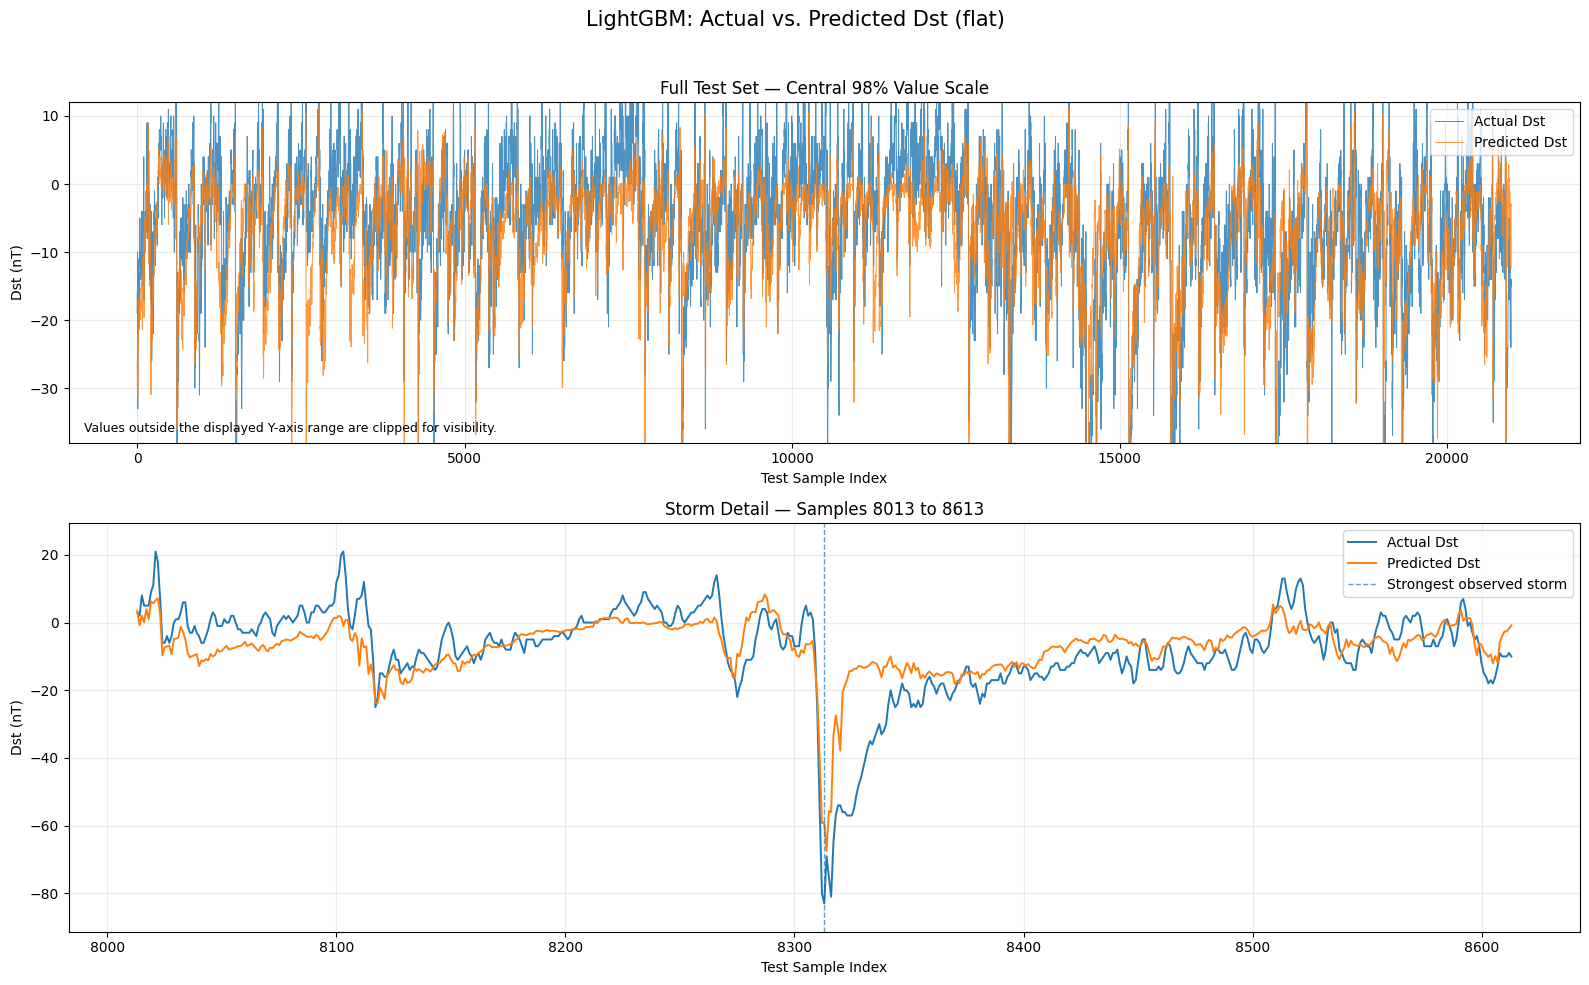

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_01_actual_vs_predicted_flat.png


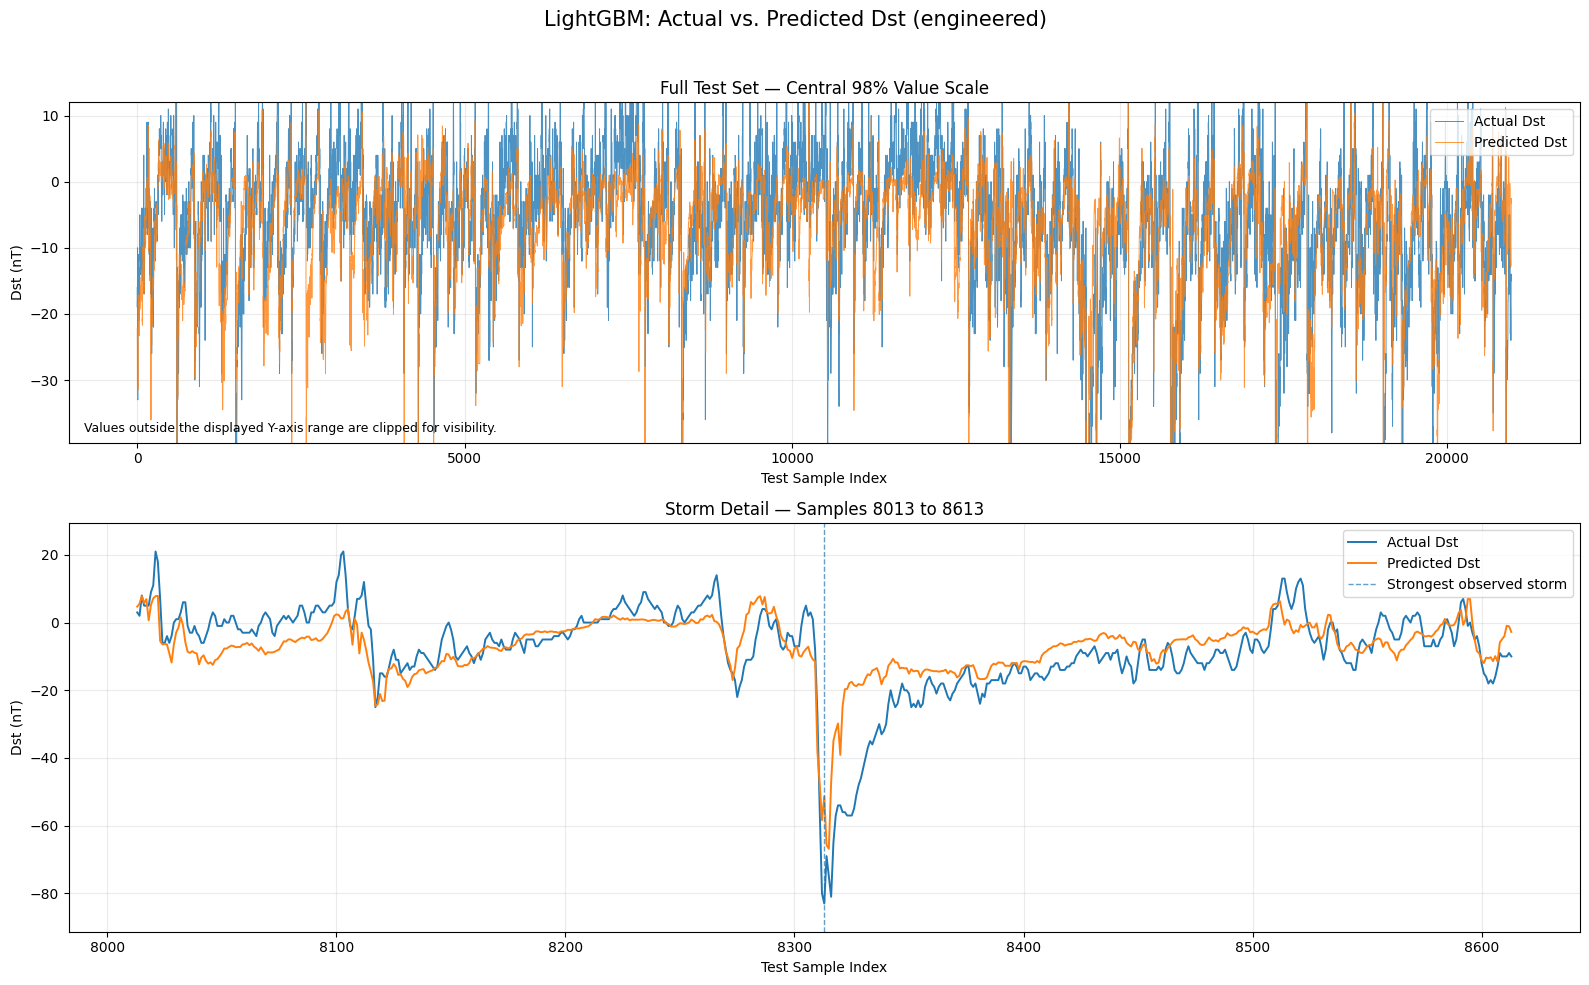

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_01_actual_vs_predicted_engineered.png


In [11]:
# Cell 8: Improved Actual vs. Predicted Dst plots

def plot_actual_vs_predicted(y_true, y_pred, representation):

    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    assert len(y_true) == len(y_pred)

    # Find the strongest observed storm in the test set
    storm_index = int(np.argmin(y_true))

    # Zoom window: 300 samples before and after the strongest storm
    window = 300
    start = max(0, storm_index - window)
    end = min(len(y_true), storm_index + window + 1)

    indices = np.arange(len(y_true))
    zoom_indices = indices[start:end]

    # Use the central 98% of combined values for overview scaling
    combined = np.concatenate([y_true, y_pred])
    y_low, y_high = np.percentile(combined, [1, 99])

    # Create two vertically stacked views
    fig, axes = plt.subplots(
        2, 1,
        figsize=(16, 10),
        gridspec_kw={"height_ratios": [1, 1.2]}
    )

    # Top: Full test-set overview
    axes[0].plot(
        indices, y_true,
        label="Actual Dst",
        linewidth=0.7,
        alpha=0.8
    )
    axes[0].plot(
        indices, y_pred,
        label="Predicted Dst",
        linewidth=0.7,
        alpha=0.8
    )

    axes[0].set_ylim(y_low, y_high)
    axes[0].set_title("Full Test Set — Central 98% Value Scale")
    axes[0].set_xlabel("Test Sample Index")
    axes[0].set_ylabel("Dst (nT)")
    axes[0].legend(loc="upper right")
    axes[0].grid(True, alpha=0.25)

    axes[0].text(
        0.01, 0.03,
        "Values outside the displayed Y-axis range are clipped for visibility.",
        transform=axes[0].transAxes,
        fontsize=9
    )

    # Bottom: Zoom around strongest observed storm
    actual_zoom = y_true[start:end]
    predicted_zoom = y_pred[start:end]

    axes[1].plot(
        zoom_indices, actual_zoom,
        label="Actual Dst",
        linewidth=1.4
    )
    axes[1].plot(
        zoom_indices, predicted_zoom,
        label="Predicted Dst",
        linewidth=1.4
    )

    zoom_min = min(actual_zoom.min(), predicted_zoom.min())
    zoom_max = max(actual_zoom.max(), predicted_zoom.max())
    padding = max((zoom_max - zoom_min) * 0.08, 2)

    axes[1].set_ylim(
        zoom_min - padding,
        zoom_max + padding
    )

    axes[1].axvline(
        storm_index,
        linestyle="--",
        linewidth=1,
        alpha=0.7,
        label="Strongest observed storm"
    )

    axes[1].set_title(
        f"Storm Detail — Samples {start} to {end - 1}"
    )
    axes[1].set_xlabel("Test Sample Index")
    axes[1].set_ylabel("Dst (nT)")
    axes[1].legend(loc="best")
    axes[1].grid(True, alpha=0.25)

    fig.suptitle(
        f"LightGBM: Actual vs. Predicted Dst ({representation})",
        fontsize=15
    )

    fig.tight_layout(rect=[0, 0, 1, 0.96])

    filename = (
        f"lightgbm_01_actual_vs_predicted_{representation}.png"
    )
    save_path = FIGURES_PATH / filename

    fig.savefig(
        save_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)


# Generate both figures using the exact test-set order
assert np.array_equal(
    flat_data["y_test"],
    engineered_data["y_test"]
)

plot_actual_vs_predicted(
    flat_data["y_test"],
    flat_test_predictions,
    "flat"
)

plot_actual_vs_predicted(
    engineered_data["y_test"],
    engineered_test_predictions,
    "engineered"
)

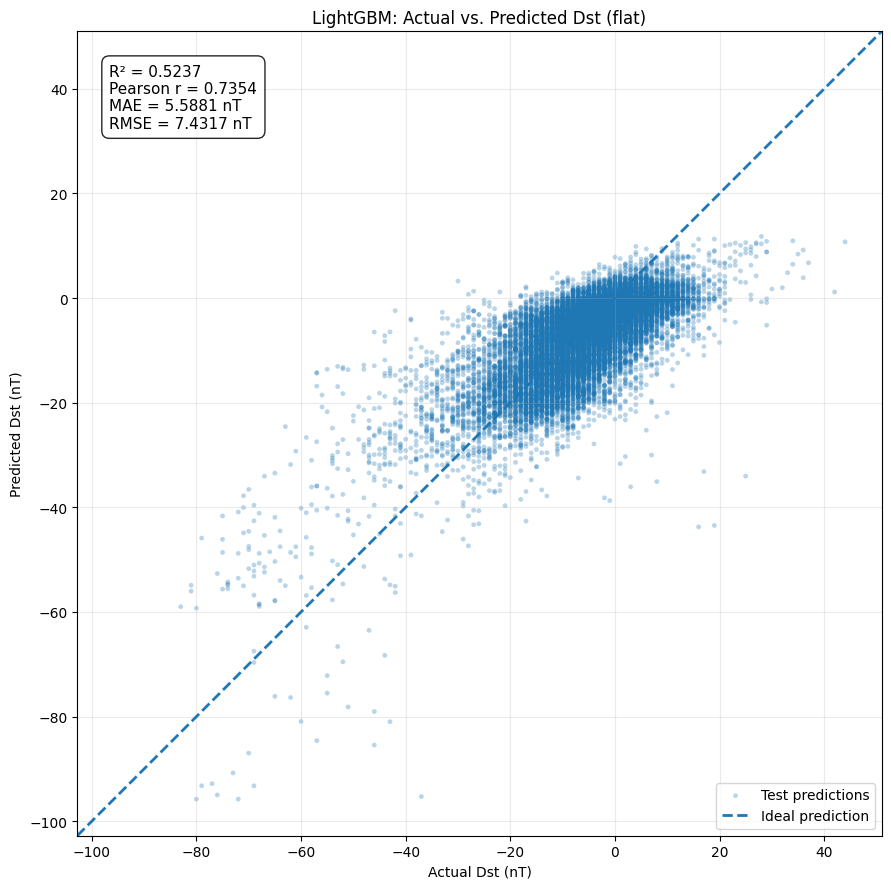

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_02_prediction_scatter_flat.png


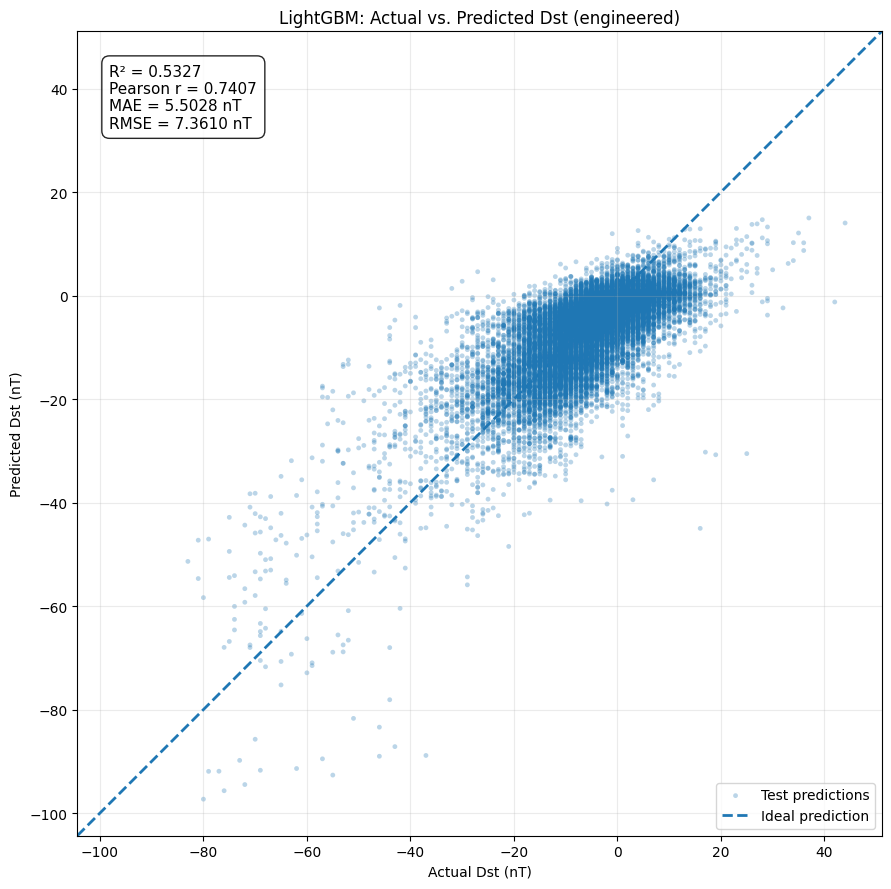

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_02_prediction_scatter_engineered.png


In [12]:
# Cell 9: Prediction scatter plots with ideal line

def plot_prediction_scatter(y_true, y_pred, representation, metrics):

    fig, ax = plt.subplots(figsize=(9, 9))

    ax.scatter(
        y_true,
        y_pred,
        s=12,
        alpha=0.3,
        edgecolors="none",
        label="Test predictions"
    )

    # Use identical limits for both axes
    lower = min(float(np.min(y_true)), float(np.min(y_pred)))
    upper = max(float(np.max(y_true)), float(np.max(y_pred)))
    padding = max((upper - lower) * 0.05, 2)

    axis_min = lower - padding
    axis_max = upper + padding

    # Ideal prediction line
    ax.plot(
        [axis_min, axis_max],
        [axis_min, axis_max],
        linestyle="--",
        linewidth=2,
        label="Ideal prediction"
    )

    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(
        f"LightGBM: Actual vs. Predicted Dst ({representation})"
    )
    ax.set_xlabel("Actual Dst (nT)")
    ax.set_ylabel("Predicted Dst (nT)")

    annotation = (
        f"R² = {metrics['R2']:.4f}\n"
        f"Pearson r = {metrics['Pearson_Correlation']:.4f}\n"
        f"MAE = {metrics['MAE']:.4f} nT\n"
        f"RMSE = {metrics['RMSE']:.4f} nT"
    )

    ax.text(
        0.04, 0.96,
        annotation,
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            alpha=0.85
        )
    )

    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.25)
    fig.tight_layout()

    filename = (
        f"lightgbm_02_prediction_scatter_{representation}.png"
    )
    save_path = FIGURES_PATH / filename

    fig.savefig(
        save_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)


plot_prediction_scatter(
    flat_data["y_test"],
    flat_test_predictions,
    "flat",
    flat_test_metrics
)

plot_prediction_scatter(
    engineered_data["y_test"],
    engineered_test_predictions,
    "engineered",
    engineered_test_metrics
)

FLAT MODEL — RMSE BY DST INTENSITY


,dst_intensity_bin,sample_count,RMSE
0,≤ -60,73,21.4181
1,"(-60, -40]",188,21.8668
2,"(-40, -20]",1441,11.0035
3,"(-20, 0]",13681,5.6220
4,> 0,5596,8.7495


ENGINEERED MODEL — RMSE BY DST INTENSITY


,dst_intensity_bin,sample_count,RMSE
0,≤ -60,73,19.3170
1,"(-60, -40]",188,21.2002
2,"(-40, -20]",1441,11.2233
3,"(-20, 0]",13681,5.7430
4,> 0,5596,8.3725


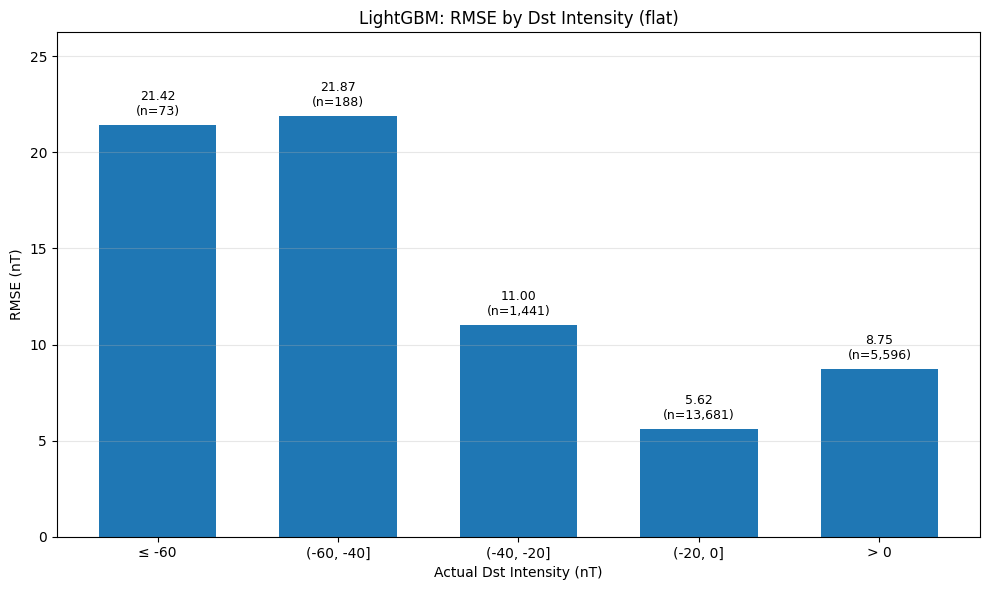

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_03_rmse_by_dst_intensity_flat.png


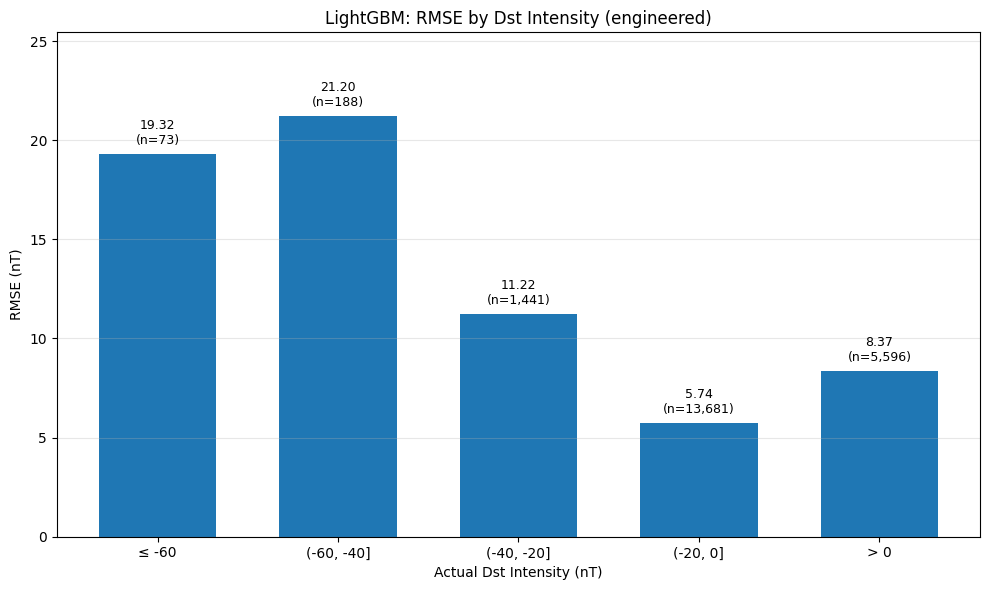

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_03_rmse_by_dst_intensity_engineered.png


In [13]:
# Cell 10: RMSE by Dst intensity

DST_BINS = [
    ("≤ -60", lambda y: y <= -60),
    ("(-60, -40]", lambda y: (y > -60) & (y <= -40)),
    ("(-40, -20]", lambda y: (y > -40) & (y <= -20)),
    ("(-20, 0]", lambda y: (y > -20) & (y <= 0)),
    ("> 0", lambda y: y > 0)
]


def calculate_rmse_by_intensity(y_true, y_pred):
    results = []

    for label, condition in DST_BINS:
        mask = condition(y_true)
        sample_count = int(np.sum(mask))

        if sample_count == 0:
            rmse = np.nan
        else:
            rmse = float(
                np.sqrt(
                    np.mean(
                        (y_true[mask] - y_pred[mask]) ** 2
                    )
                )
            )

        results.append({
            "dst_intensity_bin": label,
            "sample_count": sample_count,
            "RMSE": rmse
        })

    return pd.DataFrame(results)


# Calculate results for both representations
lightgbm_flat_intensity = calculate_rmse_by_intensity(
    flat_data["y_test"],
    flat_test_predictions
)

lightgbm_engineered_intensity = calculate_rmse_by_intensity(
    engineered_data["y_test"],
    engineered_test_predictions
)


def plot_rmse_by_intensity(results, representation):
    fig, ax = plt.subplots(figsize=(10, 6))

    labels = results["dst_intensity_bin"].tolist()
    values = results["RMSE"].to_numpy()
    counts = results["sample_count"].to_numpy()

    bars = ax.bar(labels, values, width=0.65)

    ax.set_title(
        f"LightGBM: RMSE by Dst Intensity ({representation})"
    )
    ax.set_xlabel("Actual Dst Intensity (nT)")
    ax.set_ylabel("RMSE (nT)")
    ax.grid(axis="y", alpha=0.3)

    for bar, value, count in zip(bars, values, counts):
        if np.isfinite(value):
            ax.annotate(
                f"{value:.2f}\n(n={count:,})",
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height()
                ),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9
            )
        else:
            ax.annotate(
                f"No samples\n(n={count:,})",
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    0
                ),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_ylim(
        0,
        np.nanmax(values) * 1.2
        if np.isfinite(values).any() else 1
    )
    fig.tight_layout()

    filename = (
        f"lightgbm_03_rmse_by_dst_intensity_{representation}.png"
    )
    save_path = FIGURES_PATH / filename

    fig.savefig(
        save_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)


print("FLAT MODEL — RMSE BY DST INTENSITY")
display(lightgbm_flat_intensity.round(4))

print("ENGINEERED MODEL — RMSE BY DST INTENSITY")
display(lightgbm_engineered_intensity.round(4))

plot_rmse_by_intensity(lightgbm_flat_intensity, "flat")
plot_rmse_by_intensity(lightgbm_engineered_intensity, "engineered")

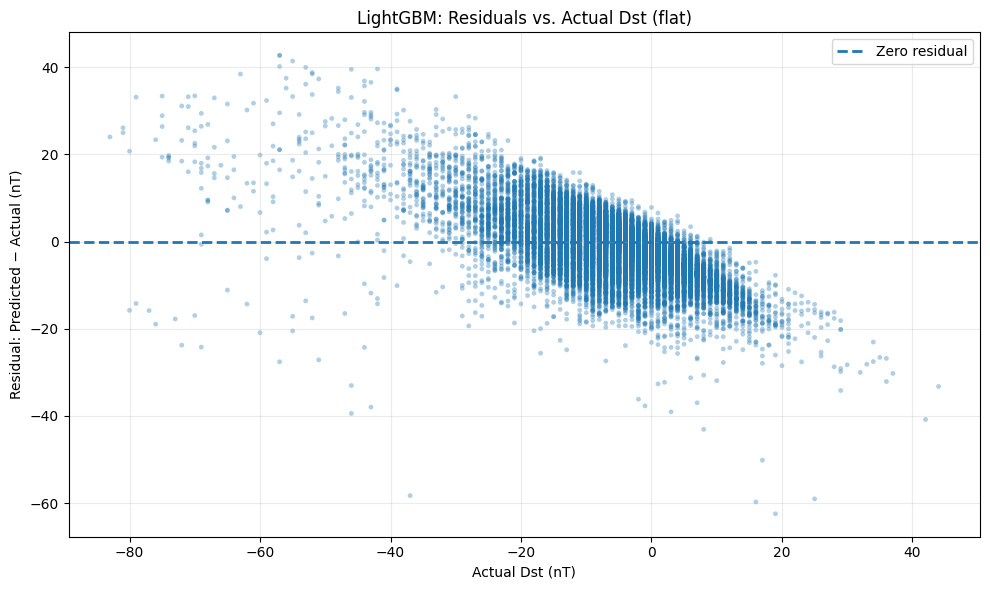

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_04_residuals_vs_actual_flat.png
Mean residual: -1.3769 nT
Residual standard deviation: 7.3030 nT


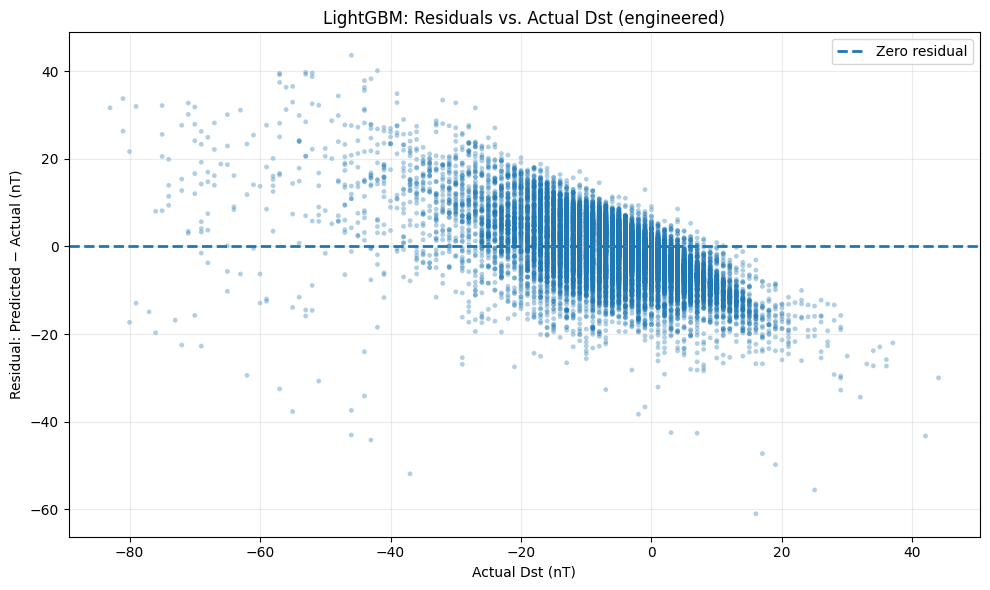

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM/lightgbm_04_residuals_vs_actual_engineered.png
Mean residual: -1.1482 nT
Residual standard deviation: 7.2709 nT


In [15]:
# Cell 11: Residuals vs. actual Dst

def plot_residuals(y_true, y_pred, representation):
    residuals = y_pred - y_true

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        y_true,
        residuals,
        s=12,
        alpha=0.35,
        edgecolors="none"
    )

    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=2,
        label="Zero residual"
    )

    ax.set_title(
        f"LightGBM: Residuals vs. Actual Dst ({representation})"
    )
    ax.set_xlabel("Actual Dst (nT)")
    ax.set_ylabel("Residual: Predicted − Actual (nT)")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

    filename = (
        f"lightgbm_04_residuals_vs_actual_{representation}.png"
    )
    save_path = FIGURES_PATH / filename

    fig.savefig(
        save_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)
    print(f"Mean residual: {np.mean(residuals):.4f} nT")
    print(
        "Residual standard deviation: "
        f"{np.std(residuals):.4f} nT"
    )


plot_residuals(
    flat_data["y_test"],
    flat_test_predictions,
    "flat"
)

plot_residuals(
    engineered_data["y_test"],
    engineered_test_predictions,
    "engineered"
)

In [16]:
# Cell 12: Save and verify the complete LightGBM experiment

from datetime import datetime, timezone
import platform
import lightgbm as lgb

# --------------------------------------------------
# 1. Save validation and test predictions
# --------------------------------------------------

prediction_arrays = {
    "lightgbm_flat_validation_predictions.npy":
        flat_model.predict(flat_data["X_val"]),
    "lightgbm_engineered_validation_predictions.npy":
        engineered_model.predict(engineered_data["X_val"]),
    "lightgbm_flat_predictions.npy":
        flat_test_predictions,
    "lightgbm_engineered_predictions.npy":
        engineered_test_predictions
}

for filename, predictions in prediction_arrays.items():
    np.save(
        RESULTS_PATH / filename,
        np.asarray(predictions, dtype=np.float32)
    )

print("Validation and test predictions saved.")


# --------------------------------------------------
# 2. Record model sizes
# --------------------------------------------------

model_paths = {
    "flat": flat_model_path,
    "engineered": engineered_model_path
}

model_sizes = {}

for name, path in model_paths.items():
    size_bytes = os.path.getsize(path)

    model_sizes[name] = {
        "model_size_bytes": int(size_bytes),
        "model_size_MB": float(size_bytes / (1024 ** 2))
    }


# --------------------------------------------------
# 3. Combine metrics and performance measurements
# --------------------------------------------------

model_runs = [
    (
        "flat",
        flat_test_metrics,
        flat_training_time,
        inference_results["flat"],
        flat_model,
        flat_data["X_train"].shape[1],
        flat_history_df
    ),
    (
        "engineered",
        engineered_test_metrics,
        engineered_training_time,
        inference_results["engineered"],
        engineered_model,
        engineered_data["X_train"].shape[1],
        engineered_history_df
    )
]

comparison_rows = []

for (
    representation,
    metrics,
    training_time,
    timing,
    model,
    n_features,
    history
) in model_runs:

    row = {
        "model": "LightGBM",
        "representation": representation,
        **metrics,
        "training_time_seconds": float(training_time),
        "final_training_RMSE": float(
            history["train_rmse"].iloc[-1]
        ),
        "final_validation_RMSE": float(
            history["validation_rmse"].iloc[-1]
        ),
        "best_validation_RMSE": float(
            history["validation_rmse"].min()
        ),
        "best_iteration": int(
            history["validation_rmse"].idxmin() + 1
        ),
        "inference_time_seconds": float(
            timing["mean_inference_time_seconds"]
        ),
        "inference_time_std_seconds": float(
            timing["std_inference_time_seconds"]
        ),
        "latency_ms_per_sample": float(
            timing["latency_ms_per_sample"]
        ),
        "throughput_samples_per_second": float(
            timing["throughput_samples_per_second"]
        ),
        "model_size_bytes": model_sizes[representation][
            "model_size_bytes"
        ],
        "model_size_MB": model_sizes[representation]["model_size_MB"],
        "n_features": int(n_features),
        "n_estimators": int(model.n_estimators_),
        "num_leaves": int(LGBM_PARAMS["num_leaves"]),
        "learning_rate": float(LGBM_PARAMS["learning_rate"]),
        "n_train_samples": int(len(flat_data["y_train"])),
        "n_validation_samples": int(len(flat_data["y_val"])),
        "n_test_samples": int(len(flat_data["y_test"]))
    }

    comparison_rows.append(row)

lightgbm_comparison_df = pd.DataFrame(comparison_rows)


# --------------------------------------------------
# 4. Save metrics as JSON and CSV
# --------------------------------------------------

metrics_output = {
    "model": "LightGBM",
    "experiment": "Geomagnetic Dst forecasting",
    "target_unit": "nT",
    "evaluation_split": "test",
    "flat": comparison_rows[0],
    "engineered": comparison_rows[1]
}

METRICS_JSON_PATH = RESULTS_PATH / "lightgbm_metrics.json"
METRICS_CSV_PATH = RESULTS_PATH / "lightgbm_metrics.csv"

with open(METRICS_JSON_PATH, "w") as f:
    json.dump(metrics_output, f, indent=4, allow_nan=False)

lightgbm_comparison_df.to_csv(
    METRICS_CSV_PATH,
    index=False
)

print("Metrics JSON and CSV saved.")


# --------------------------------------------------
# 5. Save Dst intensity results
# --------------------------------------------------

flat_intensity = lightgbm_flat_intensity.copy()
flat_intensity["representation"] = "flat"

engineered_intensity = lightgbm_engineered_intensity.copy()
engineered_intensity["representation"] = "engineered"

intensity_results = pd.concat(
    [flat_intensity, engineered_intensity],
    ignore_index=True
)

intensity_results.insert(0, "model", "LightGBM")

INTENSITY_PATH = (
    RESULTS_PATH / "lightgbm_rmse_by_dst_intensity.csv"
)

intensity_results.to_csv(
    INTENSITY_PATH,
    index=False
)

print("Dst intensity results saved.")


# --------------------------------------------------
# 6. Save experiment metadata
# --------------------------------------------------

run_metadata = {
    "model": "LightGBM",
    "experiment": "Geomagnetic Dst forecasting",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "random_seed": int(RANDOM_STATE),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "lightgbm_version": lgb.__version__,
    "training_device": "CPU",
    "parameters": LGBM_PARAMS,
    "training_protocol": {
        "boosting_rounds": int(BOOSTING_ROUNDS),
        "early_stopping": False,
        "validation_used_for_monitoring": True,
        "test_used_for_final_evaluation": True
    },
    "data_shapes": {
        "flat_train": list(flat_data["X_train"].shape),
        "flat_validation": list(flat_data["X_val"].shape),
        "flat_test": list(flat_data["X_test"].shape),
        "engineered_train": list(engineered_data["X_train"].shape),
        "engineered_validation": list(engineered_data["X_val"].shape),
        "engineered_test": list(engineered_data["X_test"].shape)
    },
    "model_files": {
        name: str(path) for name, path in model_paths.items()
    },
    "model_sizes": model_sizes
}

METADATA_PATH = RESULTS_PATH / "lightgbm_run_metadata.json"

with open(METADATA_PATH, "w") as f:
    json.dump(run_metadata, f, indent=4, allow_nan=False)

print("Run metadata saved.")


# --------------------------------------------------
# 7. Verify saved files and figures
# --------------------------------------------------

expected_files = [
    "lightgbm_parameters.json",
    "lightgbm_flat_model.txt",
    "lightgbm_engineered_model.txt",
    "lightgbm_flat_training_history.csv",
    "lightgbm_engineered_training_history.csv",
    "lightgbm_inference_timing.json",
    "lightgbm_flat_validation_predictions.npy",
    "lightgbm_engineered_validation_predictions.npy",
    "lightgbm_flat_predictions.npy",
    "lightgbm_engineered_predictions.npy",
    "lightgbm_metrics.json",
    "lightgbm_metrics.csv",
    "lightgbm_rmse_by_dst_intensity.csv",
    "lightgbm_run_metadata.json"
]

expected_figures = [
    f"lightgbm_01_actual_vs_predicted_{rep}.png"
    for rep in ("flat", "engineered")
] + [
    f"lightgbm_02_prediction_scatter_{rep}.png"
    for rep in ("flat", "engineered")
] + [
    f"lightgbm_03_rmse_by_dst_intensity_{rep}.png"
    for rep in ("flat", "engineered")
] + [
    f"lightgbm_04_residuals_vs_actual_{rep}.png"
    for rep in ("flat", "engineered")
]

missing_files = [
    name for name in expected_files
    if not (RESULTS_PATH / name).is_file()
]

missing_figures = [
    name for name in expected_figures
    if not (FIGURES_PATH / name).is_file()
]

print("\nFINAL LIGHTGBM COMPARISON")

display(
    lightgbm_comparison_df[
        [
            "model",
            "representation",
            "MAE",
            "RMSE",
            "R2",
            "Pearson_Correlation",
            "training_time_seconds",
            "latency_ms_per_sample",
            "throughput_samples_per_second",
            "model_size_MB"
        ]
    ].round(4)
)

print("\nOutput directory:", RESULTS_PATH)
print(
    f"Required files verified: "
    f"{len(expected_files) - len(missing_files)}/{len(expected_files)}"
)
print(
    f"Figures verified: "
    f"{len(expected_figures) - len(missing_figures)}/{len(expected_figures)}"
)

if missing_files:
    print("Missing files:", missing_files)

if missing_figures:
    print("Missing figures:", missing_figures)

assert not missing_files, "Some required result files are missing."
assert not missing_figures, "Some required figures are missing."

print("\nLIGHTGBM EXPERIMENT COMPLETED AND VERIFIED.")

Validation and test predictions saved.
Metrics JSON and CSV saved.
Dst intensity results saved.
Run metadata saved.

FINAL LIGHTGBM COMPARISON


,model,representation,MAE,RMSE,R2,Pearson_Correlation,training_time_seconds,latency_ms_per_sample,throughput_samples_per_second,model_size_MB
0,LightGBM,flat,5.5881,7.4317,0.5237,0.7354,92.2149,0.0199,50321.1770,0.3394
1,LightGBM,engineered,5.5028,7.3610,0.5327,0.7407,13.0235,0.0098,101780.8436,0.2859



Output directory: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/LightGBM
Required files verified: 14/14
Figures verified: 8/8

LIGHTGBM EXPERIMENT COMPLETED AND VERIFIED.
